# 02 — Baseline CNN
GPU runtime required. Evaluates on **validation only**. The test set stays untouched until final evaluation.
The `fit()` function is generic so the ResNet18 / EfficientNet notebooks can reuse it.

In [2]:
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
import os, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"     # local disk; download ART files before session ends
os.makedirs(ART, exist_ok=True)

!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/train"):
    assert "YOUR_USERNAME" not in KAGGLE_DATASET, "Edit KAGGLE_DATASET first"
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()                              # paste your Kaggle API token
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:                                   # data came as (nested) zip files
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found in the downloaded data"
    shutil.copytree(root, DATA, dirs_exist_ok=True)

print(sorted(os.listdir(DATA)))    # expect: test, train, val (+ README/csv/png)

100%|██████████| 107M/107M [00:09<00:00, 11.5MB/s]

Extracting files...


['test', 'train', 'val']


In [3]:
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)

SPLITS = ["train", "val", "test"]
CLASSES = sorted(os.listdir(f"{DATA}/train"))
rows = [(s, c, f"{DATA}/{s}/{c}/{f}") for s in SPLITS for c in CLASSES for f in os.listdir(f"{DATA}/{s}/{c}")]
df = pd.DataFrame(rows, columns=["split", "cls", "path"])

# Fill in after reviewing the near-duplicate pairs in notebook 01 (full paths to remove), else leave empty.
DROP = []
df = df[~df.path.isin(DROP)].reset_index(drop=True)

device: cuda


In [4]:
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = T.Compose([T.Resize((IMG, IMG)), T.RandomRotation(10), T.RandomAffine(0, translate=(0.05, 0.05)),
                      T.ColorJitter(brightness=0.1, contrast=0.1), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])

class MRIDataset(Dataset):
    def __init__(self, frame, tf):
        self.p, self.tf = frame.path.tolist(), tf
        self.y = [CLASSES.index(c) for c in frame.cls]
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

ds = {s: MRIDataset(df[df.split == s], train_tf if s == "train" else eval_tf) for s in SPLITS}
dl = {s: DataLoader(ds[s], batch_size=32, shuffle=(s == "train"), num_workers=2, pin_memory=True) for s in SPLITS}
n = np.bincount(ds["train"].y, minlength=len(CLASSES))
class_weights = torch.tensor(n.sum() / (len(CLASSES) * n), dtype=torch.float32).to(device)

## Model: 4 conv blocks → global average pooling → classifier
Global average pooling after a conv stack also keeps Grad-CAM straightforward later (target layer = `features[-1]`).

In [5]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))

class BaselineCNN(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

model = BaselineCNN(len(CLASSES)).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

1,174,244 parameters


## Training utilities (reusable)
Best checkpoint is chosen by **validation macro-F1** (better than accuracy under class imbalance). Early stopping on the same metric.

In [6]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); loss_sum, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            out = model(x); loss = criterion(out, y)
        loss_sum += loss.item() * len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return loss_sum / len(ys), f1_score(ys, ps, average="macro"), np.mean(np.array(ys) == np.array(ps)), ys, ps

def fit(model, name, lr=1e-3, epochs=30, patience=7, weight_decay=1e-4):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
    hist, best, bad = [], -1, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tl, tc, tn = 0.0, 0, 0
        for x, y in dl["train"]:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        vl, vf1, vacc, _, _ = evaluate(model, dl["val"], criterion)
        sched.step(vf1)
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=vacc,
                         val_macro_f1=vf1, lr=opt.param_groups[0]["lr"]))
        flag = ""
        if vf1 > best:
            best, bad, flag = vf1, 0, " *saved*"
            torch.save({"model": model.state_dict(), "classes": CLASSES, "val_macro_f1": vf1, "epoch": ep},
                       f"{ART}/{name}_best.pth")
        else:
            bad += 1
        print(f"ep {ep:02d} | train loss {tl/tn:.4f} acc {tc/tn:.3f} | val loss {vl:.4f} acc {vacc:.3f} "
              f"F1 {vf1:.3f} | {time.time()-t0:.0f}s{flag}")
        if bad >= patience: print("early stopping"); break
    json.dump(hist, open(f"{ART}/{name}_history.json", "w"))
    return pd.DataFrame(hist)

## Train

In [7]:
hist = fit(model, "baseline_cnn", lr=1e-3, epochs=30, patience=7)

ep 01 | train loss 1.0452 acc 0.551 | val loss 0.9592 acc 0.619 F1 0.624 | 34s *saved*
ep 02 | train loss 0.9198 acc 0.611 | val loss 1.2364 acc 0.504 F1 0.489 | 27s
ep 03 | train loss 0.8573 acc 0.644 | val loss 0.8172 acc 0.684 F1 0.658 | 28s *saved*
ep 04 | train loss 0.8104 acc 0.678 | val loss 0.8095 acc 0.695 F1 0.699 | 28s *saved*
ep 05 | train loss 0.7333 acc 0.717 | val loss 1.1056 acc 0.586 F1 0.589 | 27s
ep 06 | train loss 0.7093 acc 0.730 | val loss 0.6419 acc 0.752 F1 0.750 | 27s *saved*
ep 07 | train loss 0.6588 acc 0.749 | val loss 0.9953 acc 0.677 F1 0.684 | 27s
ep 08 | train loss 0.6323 acc 0.757 | val loss 0.6591 acc 0.715 F1 0.681 | 27s
ep 09 | train loss 0.5862 acc 0.768 | val loss 0.7582 acc 0.724 F1 0.737 | 27s
ep 10 | train loss 0.5138 acc 0.804 | val loss 0.5359 acc 0.809 F1 0.809 | 27s *saved*
ep 11 | train loss 0.4860 acc 0.807 | val loss 0.5862 acc 0.791 F1 0.797 | 27s
ep 12 | train loss 0.4694 acc 0.816 | val loss 0.4338 acc 0.843 F1 0.843 | 28s *saved*
ep 1

## Curves

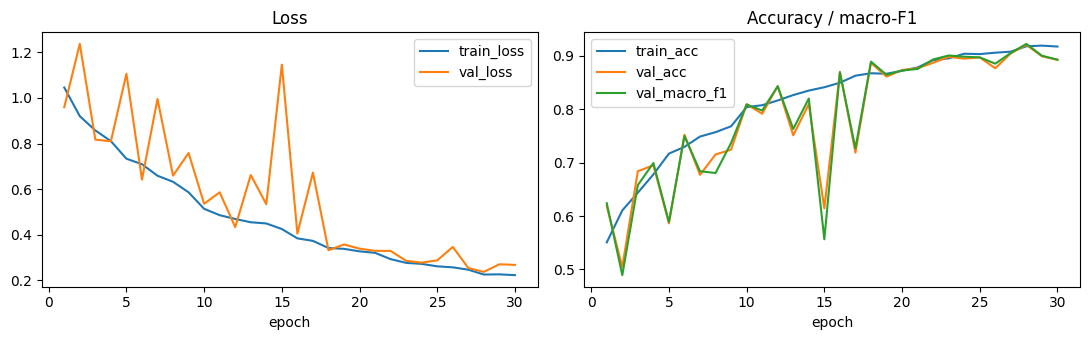

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss")
hist.plot(x="epoch", y=["train_acc", "val_acc", "val_macro_f1"], ax=ax[1], title="Accuracy / macro-F1")
plt.tight_layout(); plt.show()

## Validation report with the best checkpoint (test set still untouched)

best epoch: 28
VAL accuracy 0.9204 | macro-F1 0.9222

              precision    recall  f1-score   support

      glioma      0.958     0.891     0.923       329
  meningioma      0.874     0.874     0.874       222
    no_tumor      0.926     0.958     0.942       118
   pituitary      0.913     0.991     0.951       223

    accuracy                          0.920       892
   macro avg      0.918     0.928     0.922       892
weighted avg      0.921     0.920     0.920       892



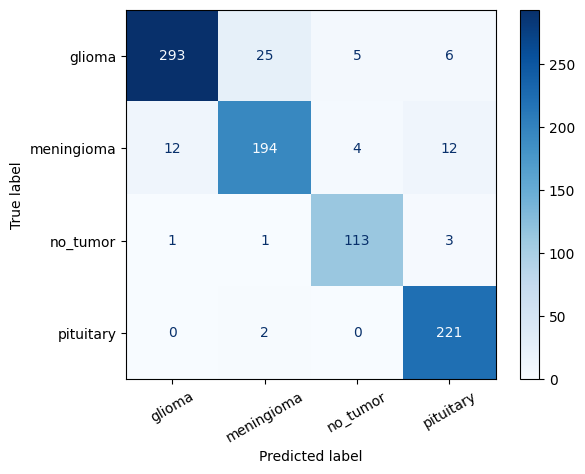

In [10]:
ck = torch.load(f"{ART}/baseline_cnn_best.pth", map_location=device)
model.load_state_dict(ck["model"])
print("best epoch:", ck["epoch"])
_, f1, acc, ys, ps = evaluate(model, dl["val"], nn.CrossEntropyLoss(weight=class_weights))
print(f"VAL accuracy {acc:.4f} | macro-F1 {f1:.4f}\n")
print(classification_report(ys, ps, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(ys, ps), display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=30)
plt.show()

## Download artifacts (checkpoint + history)
Colab's local disk is wiped when the runtime resets. Download now.

In [11]:
import shutil
from google.colab import files
shutil.make_archive("/content/neurovision_baseline", "zip", ART)
files.download("/content/neurovision_baseline.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>